<a href="https://colab.research.google.com/github/bibanaksu/PM25-Forecasting-GRU/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

In [1]:

from google.colab import files
uploaded = files.upload()

## Part 1 - Dataset audit and cleaning

### 1.1 Load the three raw files and describe them (rows, columns, types)

In [ ]:
import pandas as pd
import numpy as np
pm = pd.read_csv("pm25.csv")
gee = pd.read_csv("gee_features_daily.csv")
comb = pd.read_csv("combined_gee_pm25.csv")

files_dict = {
    "pm25.csv": pm,
    "gee_features_daily.csv": gee,
    "combined_gee_pm25.csv": comb,
}

for name, df in files_dict.items():
    print("=====", name, "=====")
    print("rows, columns:", df.shape)
    print(df.dtypes)
    print(df.head(3).to_string())
    print()

===== pm25.csv =====
rows, columns: (88041, 5)
date            object
latitude       float64
longitude      float64
pm25           float64
sensor_name     object
dtype: object
         date   latitude  longitude  pm25              sensor_name
0  2016-11-21  38.788056  -0.697222   4.0                ONTINYENT
1  2016-11-21  39.456111  -0.375833   3.0  VALÈNCIA-PISTA DE SILLA
2  2016-11-21  39.480300  -0.336400   2.0      VALÈNCIA-POLITÈCNIC

===== gee_features_daily.csv =====
rows, columns: (164208, 13)
date                    object
datetime_utc            object
id                       int64
lat                    float64
lon                    float64
temperature_celsius    float64
pressure_mb            float64
wind_u                 float64
wind_v                 float64
NO2                    float64
CO                     float64
O3                     float64
AOD                    float64
dtype: object
         date         datetime_utc  id        lat       lon  temperature_ce

### 1.2 Dates, geographical coverage and units

In [ ]:
rows = []
for name, df in files_dict.items():
    lat_col = "lat" if "lat" in df.columns else "latitude"
    lon_col = "lon" if "lon" in df.columns else "longitude"
    dates = pd.to_datetime(df["date"], errors="coerce")
    rows.append({
        "file": name,
        "n_rows": df.shape[0],
        "n_columns": df.shape[1],
        "date_min": dates.min().date(),
        "date_max": dates.max().date(),
        "lat_min": round(df[lat_col].min(), 3),
        "lat_max": round(df[lat_col].max(), 3),
        "lon_min": round(df[lon_col].min(), 3),
        "lon_max": round(df[lon_col].max(), 3),
    })
description = pd.DataFrame(rows)
print(description.to_string(index=False))

# units of each variable (taken from the project PDF and the column names)
units = {
    "pm25": "ug/m3 (target)",
    "temperature_celsius": "degree Celsius",
    "pressure_mb": "mb (= hPa)",
    "wind_u": "m/s (east-west component)",
    "wind_v": "m/s (north-south component)",
    "NO2": "mol/m2 (Sentinel-5P column, to confirm)",
    "CO": "mol/m2 (Sentinel-5P column, to confirm)",
    "O3": "mol/m2 (Sentinel-5P column, to confirm)",
    "AOD": "dimensionless",
    "latitude / longitude": "decimal degrees",
    "date": "YYYY-MM-DD (daily)",
}
for k, v in units.items():
    print(f"{k:22s} -> {v}")

                  file  n_rows  n_columns   date_min   date_max  lat_min  lat_max  lon_min  lon_max
              pm25.csv   88041          5 2016-11-21 2026-04-16   34.290   43.689   -5.663    9.446
gee_features_daily.csv  164208         13 2016-11-21 2026-04-06   36.133   43.530   -5.663    9.136
 combined_gee_pm25.csv   41718         15 2016-11-25 2026-04-06   36.133   43.530   -5.663    9.136
pm25                   -> ug/m3 (target)
temperature_celsius    -> degree Celsius
pressure_mb            -> mb (= hPa)
wind_u                 -> m/s (east-west component)
wind_v                 -> m/s (north-south component)
NO2                    -> mol/m2 (Sentinel-5P column, to confirm)
CO                     -> mol/m2 (Sentinel-5P column, to confirm)
O3                     -> mol/m2 (Sentinel-5P column, to confirm)
AOD                    -> dimensionless
latitude / longitude   -> decimal degrees
date                   -> YYYY-MM-DD (daily)


### 1.3 Missing values

In [ ]:
missing_tables = {}
for name, df in files_dict.items():
    miss = pd.DataFrame({
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
    })
    missing_tables[name] = miss
    print("=====", name, "=====")
    print(miss[miss["n_missing"] > 0] if miss["n_missing"].sum() > 0 else "no missing values")
    print()

===== pm25.csv =====
no missing values

===== gee_features_daily.csv =====
     n_missing  pct_missing
NO2      19603        11.94
CO       19603        11.94
O3       19914        12.13

===== combined_gee_pm25.csv =====
     n_missing  pct_missing
NO2       2410         5.78
CO        2410         5.78
O3        2451         5.88



### 1.4 Duplicates

In [ ]:
dup_rows = []
for name, df in files_dict.items():
    lat_col = "lat" if "lat" in df.columns else "latitude"
    lon_col = "lon" if "lon" in df.columns else "longitude"
    n_full = df.duplicated().sum()
    n_key = df.duplicated(subset=["date", lat_col, lon_col]).sum()
    if "sensor_name" in df.columns:
        n_station = df.duplicated(subset=["date", "sensor_name"]).sum()
        n_station_xy = df.duplicated(subset=["date", "sensor_name", lat_col, lon_col]).sum()
    else:
        n_station = n_station_xy = np.nan
    dup_rows.append({
        "file": name,
        "full_row_duplicates": n_full,
        "dup_date_lat_lon": n_key,
        "dup_date_sensor_name": n_station,
        "dup_date_sensor_lat_lon": n_station_xy,
    })
dup_table = pd.DataFrame(dup_rows)
print(dup_table.to_string(index=False))

# the date+sensor_name duplicates
x = pm[pm.duplicated(subset=["date", "sensor_name"], keep=False)].sort_values(["sensor_name", "date"])
print()
print("rows involved in date+sensor_name repetition:", len(x))
print("sensor names involved:", sorted(x["sensor_name"].unique()))
print(x.head(6).to_string())

                  file  full_row_duplicates  dup_date_lat_lon  dup_date_sensor_name  dup_date_sensor_lat_lon
              pm25.csv                    0                 0                1558.0                      0.0
gee_features_daily.csv                    0                 0                   NaN                      NaN
 combined_gee_pm25.csv                    0                 0                   2.0                      0.0

rows involved in date+sensor_name repetition: 3037
sensor names involved: ['Barcelona', 'LA ALJORRA', 'MOLINA DE SEGURA', 'MOMPEAN', 'SAN BASILIO', 'SSOO']
             date   latitude  longitude  pm25 sensor_name
37798  2023-05-07  41.385315     2.1538   9.0   Barcelona
37799  2023-05-07  41.387490     2.1152   9.0   Barcelona
37877  2023-05-09  41.385315     2.1538  13.0   Barcelona
37878  2023-05-09  41.387490     2.1152   8.0   Barcelona
37916  2023-05-10  41.385315     2.1538   5.0   Barcelona
37917  2023-05-10  41.387490     2.1152   7.0   Barcelona


### 1.5 Timestamps and daily regularity

In [ ]:
ts_info = {}
for name, df in files_dict.items():
    d = pd.to_datetime(df["date"], errors="coerce")
    ts_info[name] = {
        "unparsable_dates": int(d.isna().sum()),
        "date_min": d.min().date(),
        "date_max": d.max().date(),
        "is_sorted": bool(d.is_monotonic_increasing),
    }
    if "datetime_utc" in df.columns:
        dt = pd.to_datetime(df["datetime_utc"], errors="coerce")
        ts_info[name]["date_vs_datetime_mismatch"] = int((d != dt.dt.normalize()).sum())
        ts_info[name]["rows_with_hour_not_00"] = int((dt.dt.hour != 0).sum())
print(pd.DataFrame(ts_info).T.to_string())

# rows per year in pm25.csv
pm["date_dt"] = pd.to_datetime(pm["date"])
print()
print(pm["date_dt"].dt.year.value_counts().sort_index())

# last date of the GEE features vs last date of pm25.csv
gee_last = pd.to_datetime(gee["date"]).max()
print()
print("last GEE date:", gee_last.date())
print("pm25 rows after the last GEE date:", int((pm["date_dt"] > gee_last).sum()))

# daily regularity per station (station = name + coordinates)
pm["station_key"] = (pm["sensor_name"].str.strip() + "|" + pm["latitude"].astype(str)
                     + "|" + pm["longitude"].astype(str))
g = pm.groupby("station_key")["date_dt"].agg(["min", "max", "count"])
g["n_days_span"] = (g["max"] - g["min"]).dt.days + 1
g["n_missing_days"] = g["n_days_span"] - g["count"]
g["pct_missing_days"] = (100 * g["n_missing_days"] / g["n_days_span"]).round(1)
print()
print("stations:", len(g))
print(g[["count", "n_days_span", "n_missing_days", "pct_missing_days"]].describe().round(1).to_string())

                       unparsable_dates    date_min    date_max is_sorted date_vs_datetime_mismatch rows_with_hour_not_00
pm25.csv                              0  2016-11-21  2026-04-16      True                       NaN                   NaN
gee_features_daily.csv                0  2016-11-21  2026-04-06      True                         0                     0
combined_gee_pm25.csv                 0  2016-11-25  2026-04-06      True                         0                     0

date_dt
2016      312
2017     3182
2018     2563
2019     6278
2020     5618
2021     8021
2022     9489
2023    10927
2024    19101
2025    18007
2026     4543
Name: count, dtype: int64

last GEE date: 2026-04-06
pm25 rows after the last GEE date: 337

stations: 133
        count  n_days_span  n_missing_days  pct_missing_days
count   133.0        133.0           133.0             133.0
mean    662.0        888.5           226.5              17.1
std     431.4        708.1           393.3              19.

### 1.6 Station IDs and sensor identity

In [ ]:
# Station IDs and sensor identity

print("========== PM2.5 DATASET: STATION INFORMATION ==========")

# Create a normalized sensor name
pm["sensor_name_clean"] = pm["sensor_name"].str.strip()

# Basic station information
print("Unique original sensor names:", pm["sensor_name"].nunique())
print("Unique sensor names after cleaning:", pm["sensor_name_clean"].nunique())

print(
    "Unique coordinate pairs:",
    pm[["latitude", "longitude"]].drop_duplicates().shape[0]
)

print("Missing sensor names:", pm["sensor_name"].isna().sum())


# -----------------------------------------------------
# 1. FIND SENSOR NAMES WITH EXTRA SPACES
# -----------------------------------------------------

space_names = pm.loc[
    pm["sensor_name"].notna() &
    (pm["sensor_name"] != pm["sensor_name"].str.strip()),
    "sensor_name"
].unique()

print("\nNames with extra spaces:", list(space_names))


# -----------------------------------------------------
# 2. CHECK IF ONE SENSOR NAME HAS SEVERAL COORDINATES
# -----------------------------------------------------

multi_xy = pm.groupby("sensor_name_clean")[
    ["latitude", "longitude"]
].nunique()

multi_xy = multi_xy[
    (multi_xy["latitude"] > 1) |
    (multi_xy["longitude"] > 1)
]

print("\nSensor names with more than one coordinate pair:",
      len(multi_xy))

print(multi_xy.to_string())


# -----------------------------------------------------
# 3. CHECK IF ONE COORDINATE PAIR HAS SEVERAL NAMES
# -----------------------------------------------------

multi_name = pm.groupby(
    ["latitude", "longitude"]
)["sensor_name_clean"].nunique()

shared_coordinates = multi_name[multi_name > 1]

print("\nCoordinate pairs associated with multiple sensor names:",
      len(shared_coordinates))

print(shared_coordinates.to_string())


# -----------------------------------------------------
# 4. GEE FEATURES: CHECK UNIQUE IDS
# -----------------------------------------------------

print("\n========== GEE FEATURES: STATION INFORMATION ==========")

print(
    "gee_features_daily: unique IDs =",
    gee["id"].nunique()
)

print(
    "combined_gee_pm25: unique IDs =",
    comb["id"].nunique()
)

print(
    "combined_gee_pm25: unique sensor names =",
    comb["sensor_name"].nunique()
)


# -----------------------------------------------------
# 5. CHECK WHETHER ONE GEE ID HAS SEVERAL SENSOR NAMES
# -----------------------------------------------------

comb_name_check = comb.groupby("id")["sensor_name"].nunique()

ids_with_multiple_names = comb_name_check[
    comb_name_check > 1
]

print(
    "\nCombined dataset: IDs associated with multiple sensor names =",
    len(ids_with_multiple_names)
)

print(ids_with_multiple_names.to_string())


# -----------------------------------------------------
# 6. CHECK WHETHER ONE SENSOR NAME HAS SEVERAL GEE IDS
# -----------------------------------------------------

comb_id_check = comb.groupby("sensor_name")["id"].nunique()

names_with_multiple_ids = comb_id_check[
    comb_id_check > 1
]

print(
    "\nCombined dataset: sensor names associated with multiple IDs =",
    len(names_with_multiple_ids)
)

print(names_with_multiple_ids.to_string())


# -----------------------------------------------------
# 7. CHECK COORDINATE CONSISTENCY FOR GEE IDS
# -----------------------------------------------------

gee_coord_check = gee.groupby("id")[["lat", "lon"]].nunique()

gee_inconsistent_ids = gee_coord_check[
    (gee_coord_check["lat"] > 1) |
    (gee_coord_check["lon"] > 1)
]

print(
    "\nGEE features: IDs with inconsistent coordinates =",
    len(gee_inconsistent_ids)
)

comb_coord_check = comb.groupby("id")[
    ["latitude", "longitude"]
].nunique()

comb_inconsistent_ids = comb_coord_check[
    (comb_coord_check["latitude"] > 1) |
    (comb_coord_check["longitude"] > 1)
]

print(
    "Combined dataset: IDs with inconsistent coordinates =",
    len(comb_inconsistent_ids)
)

========== PM2.5 DATASET: STATION INFORMATION ==========
Unique original sensor names: 125
Unique sensor names after cleaning: 125
Unique coordinate pairs: 133
Missing sensor names: 0

Names with extra spaces: ['Estación de Franca ', 'Viladecavalls ']

Sensor names with more than one coordinate pair: 7
                   latitude  longitude
sensor_name_clean                     
Barcelona                 3          3
LA ALJORRA                2          2
MOLINA DE SEGURA          2          2
MOMPEAN                   2          2
SAN BASILIO               2          2
SSOO                      2          2
Viladecavalls             2          2

Coordinate pairs associated with multiple sensor names: 0
Series([], )

========== GEE FEATURES: STATION INFORMATION ==========
gee_features_daily: unique IDs = 100
combined_gee_pm25: unique IDs = 98
combined_gee_pm25: unique sensor names = 94

Combined dataset: IDs associated with multiple sensor names = 0
Series([], )

Combined dataset: sen

### 1.7 Coordinates

In [ ]:
coord_rows = []

for name, df in files_dict.items():
    lat_col = "lat" if "lat" in df.columns else "latitude"
    lon_col = "lon" if "lon" in df.columns else "longitude"

    coord_rows.append({
        "file": name,
        "rows_with_missing_coordinates": int(
            df[[lat_col, lon_col]].isna().any(axis=1).sum()
        ),
        "lat_out_of_range": int(
            ((df[lat_col] < -90) | (df[lat_col] > 90)).sum()
        ),
        "lon_out_of_range": int(
            ((df[lon_col] < -180) | (df[lon_col] > 180)).sum()
        ),
        "unique_coordinate_pairs": df[
            [lat_col, lon_col]
        ].drop_duplicates().shape[0],
        "latitude_range": (
            round(df[lat_col].min(), 2),
            round(df[lat_col].max(), 2)
        ),
        "longitude_range": (
            round(df[lon_col].min(), 2),
            round(df[lon_col].max(), 2)
        )
    })

coord_table = pd.DataFrame(coord_rows)

print(coord_table.to_string(index=False))

                  file  rows_with_missing_coordinates  lat_out_of_range  lon_out_of_range  unique_coordinate_pairs latitude_range longitude_range
              pm25.csv                              0                 0                 0                      133 (34.29, 43.69)   (-5.66, 9.45)
gee_features_daily.csv                              0                 0                 0                      100 (36.13, 43.53)   (-5.66, 9.14)
 combined_gee_pm25.csv                              0                 0                 0                       98 (36.13, 43.53)   (-5.66, 9.14)


### 1.8 Invalid PM2.5 values (before cleaning)

In [ ]:
for name, df in [("pm25.csv", pm), ("combined_gee_pm25.csv", comb)]:
    p = df["pm25"]
    print("=====", name, "=====")
    print("missing pm25     :", int(p.isna().sum()))
    print("pm25 <= 0        :", int((p <= 0).sum()),
          "(zeros:", int((p == 0).sum()), "| -999:", int((p == -999).sum()),
          "| other negatives:", int(((p < 0) & (p != -999)).sum()), ")")
    print("pm25 >= 500      :", int((p >= 500).sum()))
    print("min / max        :", p.min(), "/", p.max())
    print()

===== pm25.csv =====
missing pm25     : 0
pm25 <= 0        : 2093 (zeros: 1428 | -999: 96 | other negatives: 569 )
pm25 >= 500      : 19
min / max        : -999.0 / 1000.0

===== combined_gee_pm25.csv =====
missing pm25     : 0
pm25 <= 0        : 727 (zeros: 454 | -999: 4 | other negatives: 269 )
pm25 >= 500      : 8
min / max        : -999.0 / 1000.0



### 1.9 Cleaning (the rules of the project PDF)

In [ ]:
cleaning_log = []

def clean_pm25(df, name):
    df = df.copy()
    n0 = len(df)
    # step 1: remove extra spaces in station names
    df["sensor_name"] = df["sensor_name"].str.strip()
    # step 2: missing PM2.5
    mask_na = df["pm25"].isna()
    n_na = int(mask_na.sum())
    df = df[~mask_na]
    # step 3: invalid sentinel values (<= 0 or >= 500)
    mask_low = df["pm25"] <= 0
    mask_high = df["pm25"] >= 500
    n_low = int(mask_low.sum())
    n_high = int(mask_high.sum())
    df = df[~(mask_low | mask_high)]
    n1 = len(df)
    cleaning_log.append({
        "file": name, "rows_before": n0, "removed_missing_pm25": n_na,
        "removed_pm25_le_0": n_low, "removed_pm25_ge_500": n_high,
        "removed_total": n0 - n1, "rows_after": n1,
        "pct_removed": round(100 * (n0 - n1) / n0, 2),
    })
    return df.reset_index(drop=True)

pm_clean = clean_pm25(pm[["date", "latitude", "longitude", "pm25", "sensor_name"]], "pm25.csv")
comb_clean = clean_pm25(comb, "combined_gee_pm25.csv")

log_df = pd.DataFrame(cleaning_log)
print(log_df.T.to_string())

# duplicates: none found
# (date, sensor, lat, lon) so no row is dropped for duplicates.
print()
print("full-row duplicates left (pm25):", int(pm_clean.duplicated().sum()))
print("key duplicates left (pm25):", int(pm_clean.duplicated(subset=["date", "sensor_name", "latitude", "longitude"]).sum()))

                             0                      1
file                  pm25.csv  combined_gee_pm25.csv
rows_before              88041                  41718
removed_missing_pm25         0                      0
removed_pm25_le_0         2093                    727
removed_pm25_ge_500         19                      8
removed_total             2112                    735
rows_after               85929                  40983
pct_removed                2.4                   1.76

full-row duplicates left (pm25): 0
key duplicates left (pm25): 0


### 1.10 Checks after cleaning

In [ ]:
for name, df in [
    ("pm25_clean", pm_clean),
    ("combined_clean", comb_clean)
]:
    print("=====", name, "=====")
    print("Shape:", df.shape)
    print("Missing PM2.5:", int(df["pm25"].isna().sum()))
    print("PM2.5 min / max:", df["pm25"].min(), "/", df["pm25"].max())
    print("Date range:", df["date"].min(), "->", df["date"].max())
    print("Unique sensor names:", df["sensor_name"].nunique())
    print("PM2.5 statistics:")
    print(df["pm25"].describe().round(2).to_string())
    print("Full-row duplicates:", int(df.duplicated().sum()))
    print()

lost = (
    set(pm["sensor_name"].dropna().str.strip())
    - set(pm_clean["sensor_name"].dropna().str.strip())
)

print("Stations with no valid row left after cleaning:", len(lost))
print("Station names:", sorted(lost))

===== pm25_clean =====
Shape: (85929, 5)
Missing PM2.5: 0
PM2.5 min / max: 0.0066666666666666 / 484.9815
Date range: 2016-11-21 -> 2026-04-16
Unique sensor names: 118
PM2.5 statistics:
count    85929.00
mean         9.66
std          8.81
min          0.01
25%          4.86
50%          8.04
75%         12.54
max        484.98
Full-row duplicates: 0

===== combined_clean =====
Shape: (40983, 15)
Missing PM2.5: 0
PM2.5 min / max: 0.0066666666666666 / 484.9815
Date range: 2016-11-25 -> 2026-04-06
Unique sensor names: 91
PM2.5 statistics:
count    40983.00
mean         9.46
std          9.73
min          0.01
25%          4.67
50%          7.85
75%         12.09
max        484.98
Full-row duplicates: 0

Stations with no valid row left after cleaning: 7
Station names: ['064F', 'balcon SE pas de vent', 'balcon SE à 150m', 'grasse', 'mimiz', "réunion capt'air citoyen", 'testcompnex']


### 1.11 Save the cleaned files

In [ ]:
pm_clean.to_csv("pm25_clean.csv", index=False, encoding="utf-8")
comb_clean.to_csv("combined_gee_pm25_clean.csv", index=False, encoding="utf-8")
log_df.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
print("files saved")

files saved


### 1.12 Cleaning report (`cleaning_report.txt`)

In [ ]:
lines = []
L = lines.append
a = log_df.set_index("file")

L("CLEANING REPORT - PM2.5 FORECASTING MINI PROJECT")
L("Part: dataset audit and cleaning")
L("=" * 60)
L("")
L("1. DATASET DESCRIPTION")
L("-" * 60)
L("Source  : Kaggle dataset 'Air Quality - Mediterranean Basin (2016-2026)'")
L("          (link given in the project PDF, author: sarahameziane).")
L("          PM2.5 comes from air-quality monitoring stations (pm25.csv);")
L("          meteorological, AOD, NO2, CO and O3 variables come from Google")
L("          Earth Engine (GEE) files.")
L("License : not written in the CSV files. To be copied from the 'License'")
L("          field of the Kaggle page before the final report.")
L("Target  : pm25 = daily surface PM2.5 concentration, in ug/m3.")
L("")
L("Files received:")
for _, r in description.iterrows():
    L(f"  - {r['file']}: {r['n_rows']} rows x {r['n_columns']} columns, "
      f"dates {r['date_min']} -> {r['date_max']}, "
      f"lat {r['lat_min']} to {r['lat_max']}, lon {r['lon_min']} to {r['lon_max']}")
L("")
L("Units:")
for k, v in units.items():
    L(f"  - {k}: {v}")
L("")
L(f"Geographical coverage: western Mediterranean basin (mainly Spain), latitude "
  f"{pm['latitude'].min():.2f} to {pm['latitude'].max():.2f}, longitude "
  f"{pm['longitude'].min():.2f} to {pm['longitude'].max():.2f}.")
L(f"Time coverage: {pm['date'].min()} to {pm['date'].max()} (daily data) in pm25.csv; "
  f"GEE features stop on {gee_last.date()}.")
L("")
L("2. MISSING VALUES")
L("-" * 60)
for name, miss in missing_tables.items():
    m = miss[miss["n_missing"] > 0]
    if len(m) == 0:
        L(f"  - {name}: no missing value in any column (pm25 included).")
    else:
        txt = ", ".join(f"{i} = {int(r.n_missing)} ({r.pct_missing}%)" for i, r in m.iterrows())
        L(f"  - {name}: {txt}. No missing value in the other columns.")
L("  Only NO2, CO and O3 (Sentinel-5P) have missing values. They are NOT filled here:")
L("  imputation must be done inside each training fold (project PDF, section 5.3.1).")
L("")
L("3. DUPLICATE RECORDS")
L("-" * 60)
for _, r in dup_table.iterrows():
    L(f"  - {r['file']}: full-row duplicates = {r['full_row_duplicates']}, "
      f"(date, lat, lon) duplicates = {r['dup_date_lat_lon']}")
L(f"  In pm25.csv, {int(dup_table.loc[0, 'dup_date_sensor_name'])} rows repeat the same date and "
  "sensor_name, but with different coordinates (6 names: Barcelona, LA ALJORRA,")
L("  MOLINA DE SEGURA, MOMPEAN, SAN BASILIO, SSOO). They are different measuring")
L("  points with the same name, not duplicates, so they are kept.")
L("  Result: no duplicate row to remove.")
L("")
L("4. TIMESTAMPS")
L("-" * 60)
L("  - All dates can be parsed (0 invalid date) and all files are sorted by date.")
L("  - In the GEE files, datetime_utc always equals date at 00:00:00 (0 mismatch),")
L("    so the data are daily.")
L(f"  - pm25.csv has {int((pm['date_dt'] > gee_last).sum())} rows after the last GEE date "
  f"({gee_last.date()}): they have no features.")
L(f"  - Daily regularity: {len(g)} stations (name + coordinates). Median span of "
  f"{g['n_days_span'].median():.0f} days with median {g['pct_missing_days'].median():.1f}% missing days;")
L(f"    the number of days per station goes from {int(g['count'].min())} to {int(g['count'].max())}.")
L("    The series are irregular and do not start/end on the same dates. No gap is")
L("    filled at this stage (no interpolation).")
L("")
L("5. STATION IDs")
L("-" * 60)
L(f"  - pm25.csv has {pm['sensor_name'].nunique()} sensor names and "
  f"{pm[['latitude','longitude']].drop_duplicates().shape[0]} different coordinate pairs; no missing name.")
L("  - 7 names have more than one coordinate pair (the 6 above + Viladecavalls).")
L("    Rule used by the group: a station = sensor_name + latitude + longitude.")
L("  - No coordinate pair is shared by two different names.")
L("  - 2 names had a space at the end ('Estación de Franca ', 'Viladecavalls '):")
L("    spaces removed.")
L(f"  - GEE files use a numeric id: {gee['id'].nunique()} ids in gee_features_daily.csv, "
  f"{comb['id'].nunique()} ids and {comb['sensor_name'].nunique()} names in combined_gee_pm25.csv.")
L("    Each id has one single coordinate pair and one single name; 4 names (LA ALJORRA,")
L("    MOLINA DE SEGURA, MOMPEAN, SAN BASILIO) have 2 ids, which is consistent with")
L("    their 2 coordinate pairs.")
L("")
L("6. COORDINATES")
L("-" * 60)
L("  - No missing latitude/longitude, none outside [-90, 90] / [-180, 180] in any file.")
L("  - All points are inside the western Mediterranean area given above.")
L(f"  - {pm[['latitude','longitude']].drop_duplicates().shape[0]} distinct points in pm25.csv, "
  f"{gee[['lat','lon']].drop_duplicates().shape[0]} in gee_features_daily.csv, "
  f"{comb[['latitude','longitude']].drop_duplicates().shape[0]} in combined_gee_pm25.csv.")
L("  - The GEE ids are fixed to one point each, so coordinates are reliable for")
L("    spatial CV. Matching pm25 stations to GEE ids (about 0.25 degree) is a later step.")
L("")
L("7. INVALID PM2.5 VALUES (before cleaning)")
L("-" * 60)
for name, df in [("pm25.csv", pm), ("combined_gee_pm25.csv", comb)]:
    p = df["pm25"]
    L(f"  - {name}: missing = {int(p.isna().sum())}, pm25 <= 0 = {int((p <= 0).sum())} "
      f"(zeros {int((p == 0).sum())}, -999 {int((p == -999).sum())}, other negatives "
      f"{int(((p < 0) & (p != -999)).sum())}), pm25 >= 500 = {int((p >= 500).sum())}, "
      f"min = {p.min()}, max = {p.max()}")
L("")
L("8. CLEANING STEPS")
L("-" * 60)
L("  Step 1: remove the spaces at the beginning/end of sensor_name.")
L("  Step 2: remove rows with missing PM2.5 (none found).")
L("  Step 3: remove rows with PM2.5 <= 0 (sentinel -999, zeros and negative values,")
L("          which are not valid concentrations).")
L("  Step 4: remove rows with PM2.5 >= 500 (invalid sentinel values, rule of the PDF).")
L("  Step 5: duplicates, timestamps and coordinates: checked, nothing to remove.")
L("  Nothing else is changed: valid extreme PM2.5 values below 500 are kept (they can")
L("  be real pollution episodes), NO2/CO/O3 are not imputed, no outlier removal,")
L("  no scaling, no lag creation.")
L("  The rules are applied before EDA and before any split, as asked in section 5.1.")
L("")
L("  Counts:")
for f, r in a.iterrows():
    L(f"  - {f}: {int(r['rows_before'])} rows before; removed missing = {int(r['removed_missing_pm25'])}, "
      f"<= 0 = {int(r['removed_pm25_le_0'])}, >= 500 = {int(r['removed_pm25_ge_500'])}; "
      f"total removed = {int(r['removed_total'])} ({r['pct_removed']}%); {int(r['rows_after'])} rows after.")
L("")
L("9. RESULT AFTER CLEANING")
L("-" * 60)
for name, df in [("pm25_clean.csv", pm_clean), ("combined_gee_pm25_clean.csv", comb_clean)]:
    L(f"  - {name}: {df.shape[0]} rows x {df.shape[1]} columns, {df['sensor_name'].nunique()} sensor names, "
      f"dates {df['date'].min()} -> {df['date'].max()}, pm25 min = {df['pm25'].min():.3f}, "
      f"max = {df['pm25'].max():.2f}, mean = {df['pm25'].mean():.2f}, median = {df['pm25'].median():.2f}.")
L(f"  - {len(lost)} station names in pm25.csv have no valid row left after cleaning.")
L("  - Checks after cleaning: no missing PM2.5, no value <= 0 or >= 500, no duplicate.")
L("")
L("10. FILES SHARED WITH THE GROUP")
L("-" * 60)
L("  - pm25_clean.csv")
L("  - combined_gee_pm25_clean.csv")
L("  - cleaning_log.csv (row counts of each step)")
L("  - cleaning_report.txt (this file)")
L("  gee_features_daily.csv is unchanged (it has no PM2.5 column).")
L("")

with open("cleaning_report.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
print("\n".join(lines))

CLEANING REPORT - PM2.5 FORECASTING MINI PROJECT
Part: dataset audit and cleaning

1. DATASET DESCRIPTION
------------------------------------------------------------
Source  : Kaggle dataset 'Air Quality - Mediterranean Basin (2016-2026)'
          (link given in the project PDF, author: sarahameziane).
          PM2.5 comes from air-quality monitoring stations (pm25.csv);
          meteorological, AOD, NO2, CO and O3 variables come from Google
          Earth Engine (GEE) files.
License : not written in the CSV files. To be copied from the 'License'
          field of the Kaggle page before the final report.
Target  : pm25 = daily surface PM2.5 concentration, in ug/m3.

Files received:
  - pm25.csv: 88041 rows x 5 columns, dates 2016-11-21 -> 2026-04-16, lat 34.29 to 43.689, lon -5.663 to 9.446
  - gee_features_daily.csv: 164208 rows x 13 columns, dates 2016-11-21 -> 2026-04-06, lat 36.133 to 43.53, lon -5.663 to 9.136
  - combined_gee_pm25.csv: 41718 rows x 15 columns, dates 2016-11

## Part 2 - Exploratory data analysis (EDA)


### 2.1 Load the cleaned dataset

In [ ]:
df = pd.read_csv("combined_gee_pm25_clean.csv")

print("Dataset shape:", df.shape)

Dataset shape: (40983, 15)


In [ ]:
print(df.head().to_string())


         date         datetime_utc  id   latitude  longitude  temperature_celsius  pressure_mb    wind_u    wind_v  NO2  CO  O3     AOD       pm25              sensor_name
0  2016-11-25  2016-11-25 00:00:00   1  38.788056  -0.697222             6.493180   946.288660  0.230240  0.735303  NaN NaN NaN  0.1110   2.750000                ONTINYENT
1  2016-11-25  2016-11-25 00:00:00  36  39.945278  -0.056389             9.251236   993.626994  0.783218 -0.592618  NaN NaN NaN  0.0220  11.666667  ALMASSORA-C. P. OCHANDO
2  2016-11-30  2016-11-30 00:00:00  35  40.051944  -0.189722            10.044782   981.911432 -2.211047 -1.568971  NaN NaN NaN  0.2380   2.400000                   ALCORA
3  2016-11-30  2016-11-30 00:00:00  37  40.062222   0.072778            12.299584  1008.794766 -3.236886 -2.804465  NaN NaN NaN  0.2480   2.600000               BENICASSIM
4  2016-12-02  2016-12-02 00:00:00   1  38.788056  -0.697222             9.350630   953.114180  0.953454  0.293060  NaN NaN NaN  0.0755   2.

In [ ]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 40983 entries, 0 to 40982
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 40983 non-null  str    
 1   datetime_utc         40983 non-null  str    
 2   id                   40983 non-null  int64  
 3   latitude             40983 non-null  float64
 4   longitude            40983 non-null  float64
 5   temperature_celsius  40983 non-null  float64
 6   pressure_mb          40983 non-null  float64
 7   wind_u               40983 non-null  float64
 8   wind_v               40983 non-null  float64
 9   NO2                  38576 non-null  float64
 10  CO                   38576 non-null  float64
 11  O3                   38535 non-null  float64
 12  AOD                  40983 non-null  float64
 13  pm25                 40983 non-null  float64
 14  sensor_name          40983 non-null  str    
dtypes: float64(11), int64(1), 

In [ ]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print(missing)

                     Missing Values  Missing Percentage
date                              0                0.00
datetime_utc                      0                0.00
id                                0                0.00
latitude                          0                0.00
longitude                         0                0.00
temperature_celsius               0                0.00
pressure_mb                       0                0.00
wind_u                            0                0.00
wind_v                            0                0.00
NO2                            2407                5.87
CO                             2407                5.87
O3                             2448                5.97
AOD                               0                0.00
pm25                              0                0.00
sensor_name                       0                0.00


In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,40983.0,52.73,35.03,0.00,21.00,50.00,90.00,109.00
latitude,40983.0,39.03,2.23,36.13,36.84,39.45,40.05,43.53
longitude,40983.0,-0.47,3.83,-5.66,-3.61,-0.41,1.15,9.14
temperature_celsius,40983.0,18.27,6.39,-1.28,12.97,18.49,23.79,34.87
pressure_mb,40983.0,993.82,17.18,930.32,987.99,997.73,1005.37,1033.66
wind_u,40983.0,0.34,2.53,-11.10,-0.98,0.21,1.68,9.66
wind_v,40983.0,-0.18,1.39,-10.86,-0.73,0.04,0.66,8.49
NO2,38576.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CO,38576.0,0.03,0.00,0.01,0.03,0.03,0.03,0.10
O3,38535.0,0.14,0.01,0.10,0.13,0.14,0.15,0.23


### 2.2 Distribution and outliers of the main variables (histogram + boxplot + IQR rule)

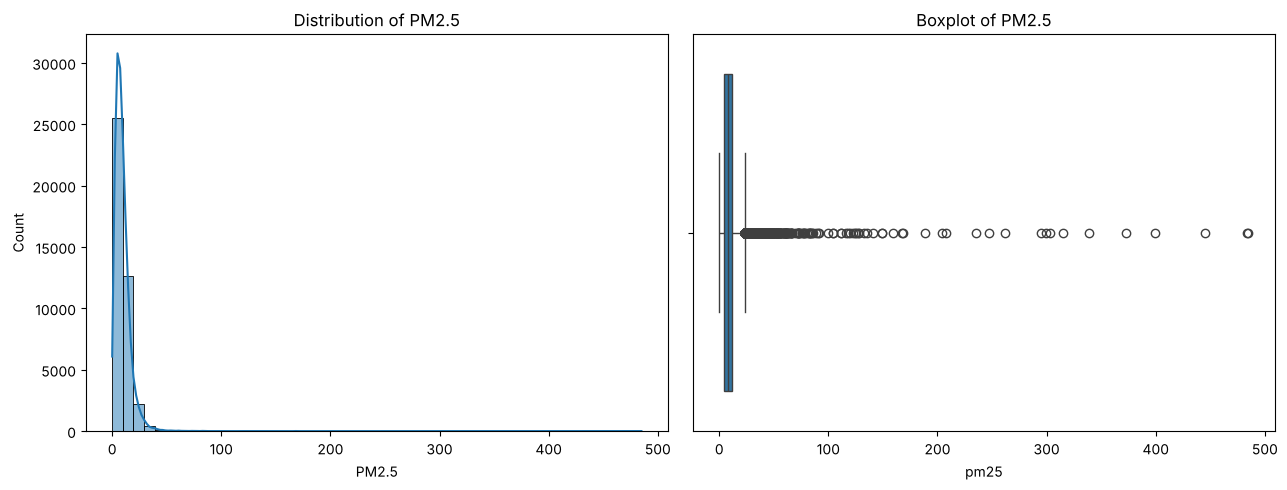

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["pm25"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution of PM2.5")
axes[0].set_xlabel("PM2.5")

sns.boxplot(x=df["pm25"], ax=axes[1])
axes[1].set_title("Boxplot of PM2.5")

plt.tight_layout()
plt.show()

In [ ]:
q1 = df["pm25"].quantile(0.25)
q3 = df["pm25"].quantile(0.75)

iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = df[df["pm25"] > upper]

print("Skewness:", round(df["pm25"].skew(), 2))
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("Upper bound:", round(upper, 2))
print("Number of outliers:", len(outliers))

Skewness: 17.83
Q1: 4.67
Q3: 12.09
Upper bound: 23.21
Number of outliers: 1613


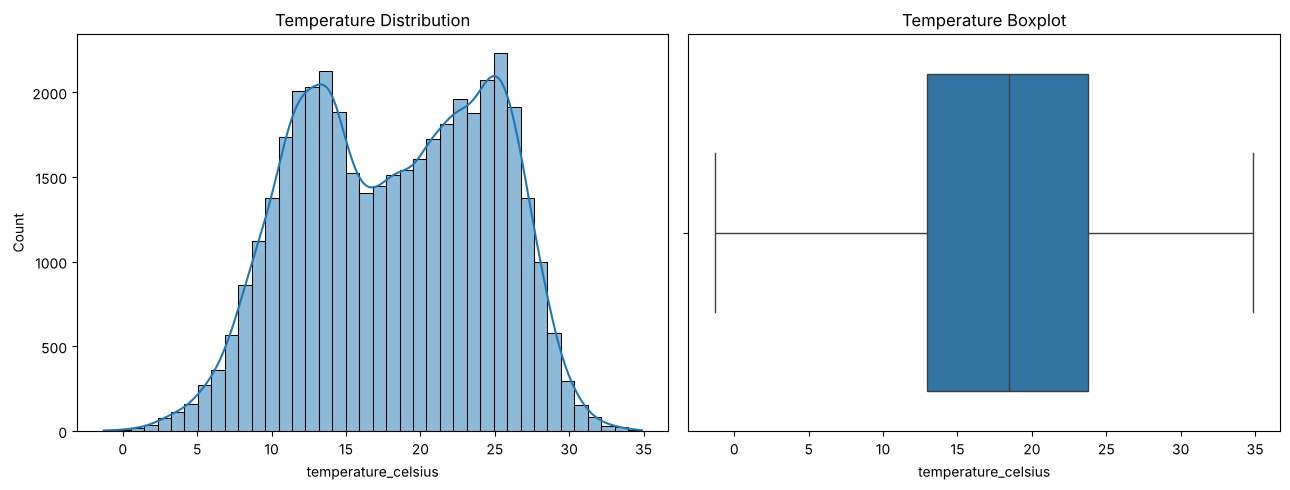

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["temperature_celsius"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Temperature Distribution")

sns.boxplot(x=df["temperature_celsius"], ax=axes[1])
axes[1].set_title("Temperature Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
q1 = df["temperature_celsius"].quantile(0.25)
q3 = df["temperature_celsius"].quantile(0.75)

iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

outliers = df[
    (df["temperature_celsius"] < lower) |
    (df["temperature_celsius"] > upper)
]

print("Skewness:", round(df["temperature_celsius"].skew(), 2))
print("Lower bound:", round(lower, 2))
print("Upper bound:", round(upper, 2))
print("Number of outliers:", len(outliers))

Skewness: -0.1
Lower bound: -3.27
Upper bound: 40.02
Number of outliers: 0


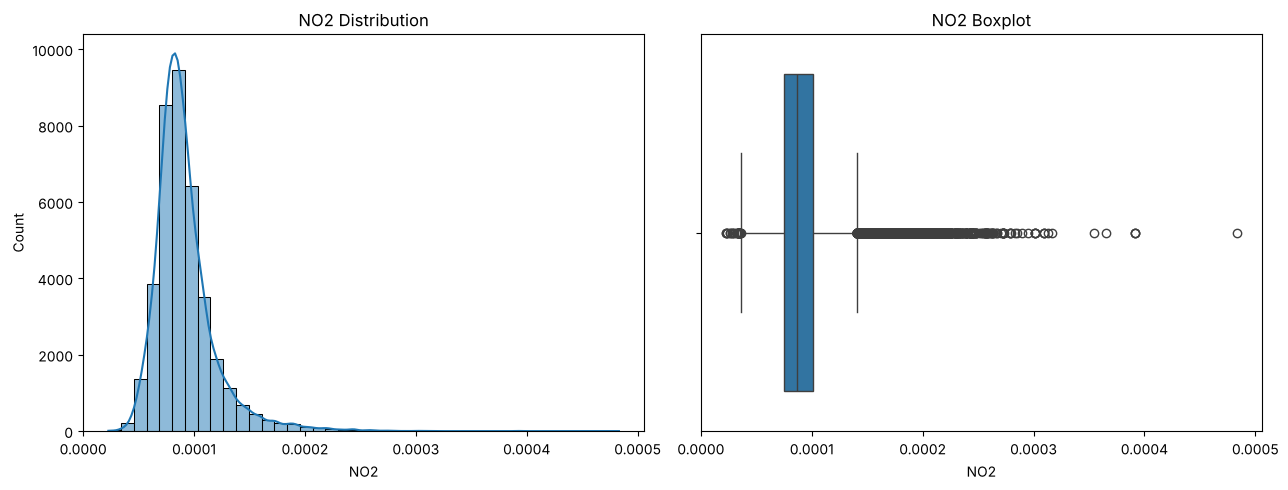

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["NO2"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("NO2 Distribution")

sns.boxplot(x=df["NO2"].dropna(), ax=axes[1])
axes[1].set_title("NO2 Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
col = "NO2"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.8f}")
print("Upper bound:", f"{upper:.8f}")
print("Number of outliers:", len(outliers))

Skewness: 2.12
Lower bound: 0.00003596
Upper bound: 0.00014038
Number of outliers: 2061


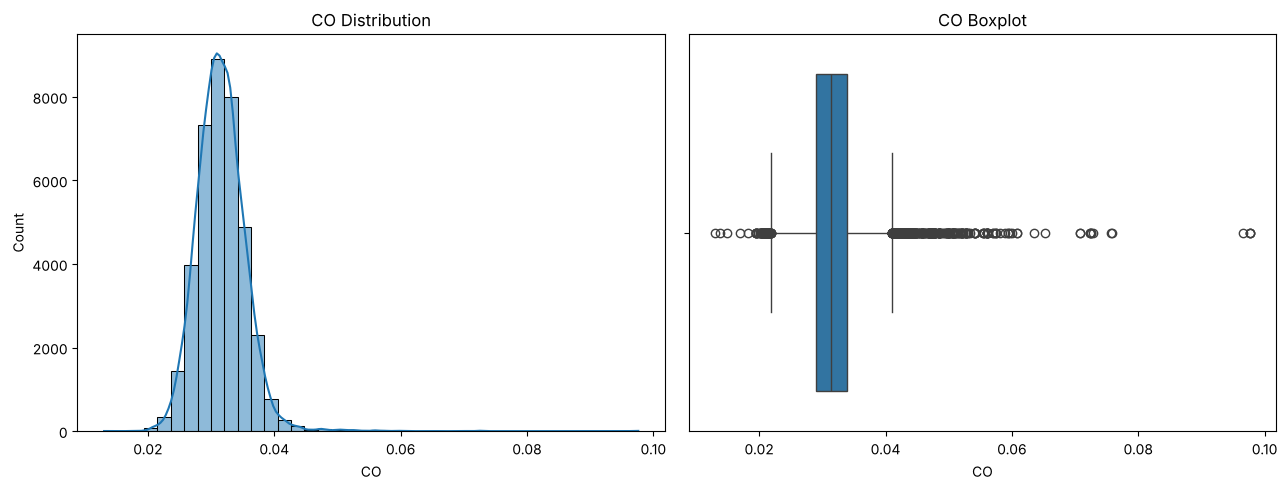

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["CO"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("CO Distribution")

sns.boxplot(x=df["CO"].dropna(), ax=axes[1])
axes[1].set_title("CO Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
col = "CO"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.6f}")
print("Upper bound:", f"{upper:.6f}")
print("Number of outliers:", len(outliers))

Skewness: 1.4
Lower bound: 0.021862
Upper bound: 0.041005
Number of outliers: 572


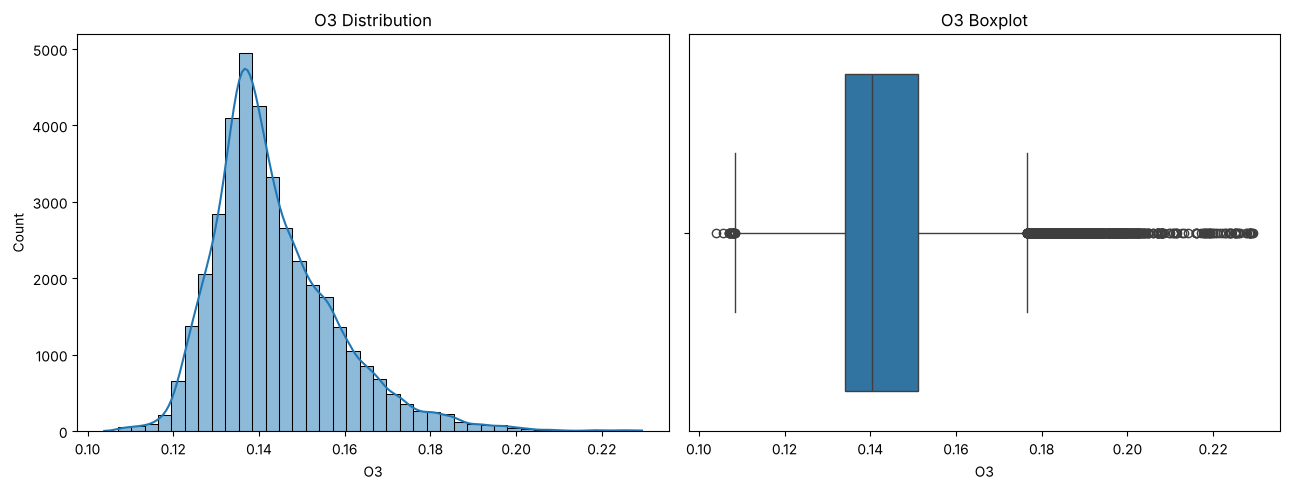

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["O3"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("O3 Distribution")

sns.boxplot(x=df["O3"].dropna(), ax=axes[1])
axes[1].set_title("O3 Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
col = "O3"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.6f}")
print("Upper bound:", f"{upper:.6f}")
print("Number of outliers:", len(outliers))

Skewness: 1.15
Lower bound: 0.108476
Upper bound: 0.176592
Number of outliers: 1219


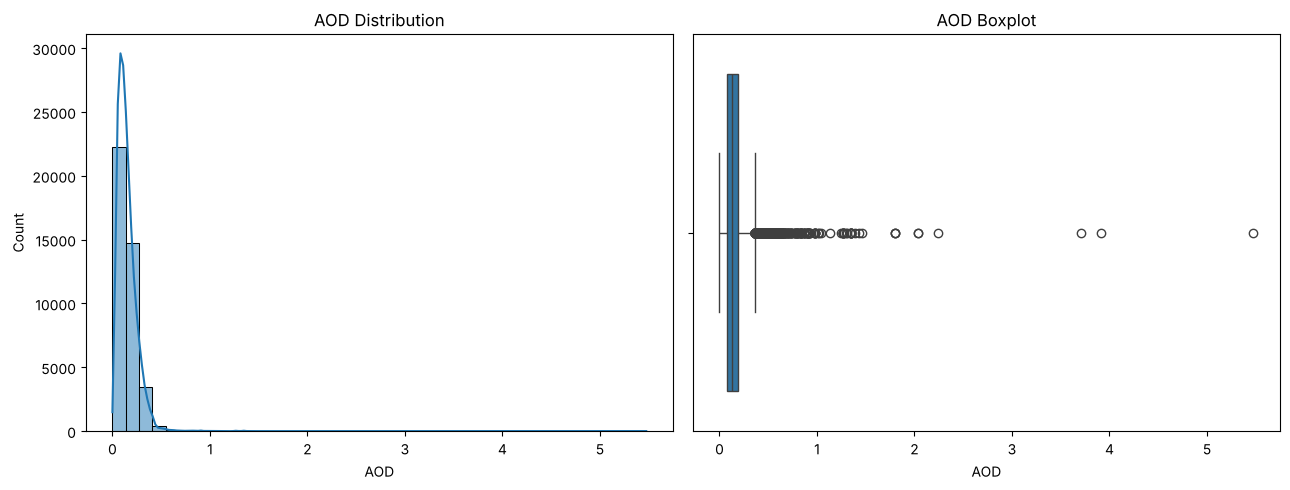

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["AOD"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("AOD Distribution")

sns.boxplot(x=df["AOD"], ax=axes[1])
axes[1].set_title("AOD Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
col = "AOD"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.6f}")
print("Upper bound:", f"{upper:.6f}")
print("Number of outliers:", len(outliers))

Skewness: 7.61
Lower bound: -0.091000
Upper bound: 0.365000
Number of outliers: 1114


### 2.3 Correlations (Pearson and Spearman)

In [ ]:
numeric_df = df.select_dtypes(include="number").drop(columns=["id"])

pearson_corr = numeric_df.corr(method="pearson")
spearman_corr = numeric_df.corr(method="spearman")

print("PEARSON CORRELATION")
print(pearson_corr.round(2).to_string())

print("\nSPEARMAN CORRELATION")
print(spearman_corr.round(2).to_string())

PEARSON CORRELATION
                     latitude  longitude  temperature_celsius  pressure_mb  wind_u  wind_v   NO2    CO    O3   AOD  pm25
latitude                 1.00       0.81                -0.14         0.07    0.12   -0.20  0.17  0.16  0.14 -0.03 -0.05
longitude                0.81       1.00                -0.10         0.07    0.13   -0.21  0.02  0.17  0.12 -0.00 -0.02
temperature_celsius     -0.14      -0.10                 1.00        -0.06   -0.18    0.34 -0.06 -0.13 -0.32  0.33 -0.01
pressure_mb              0.07       0.07                -0.06         1.00   -0.09   -0.04  0.17  0.20 -0.03  0.02  0.11
wind_u                   0.12       0.13                -0.18        -0.09    1.00   -0.22 -0.09  0.03  0.16 -0.25 -0.08
wind_v                  -0.20      -0.21                 0.34        -0.04   -0.22    1.00  0.11 -0.07 -0.12  0.16  0.06
NO2                      0.17       0.02                -0.06         0.17   -0.09    0.11  1.00  0.10 -0.09 -0.06  0.16
CO          

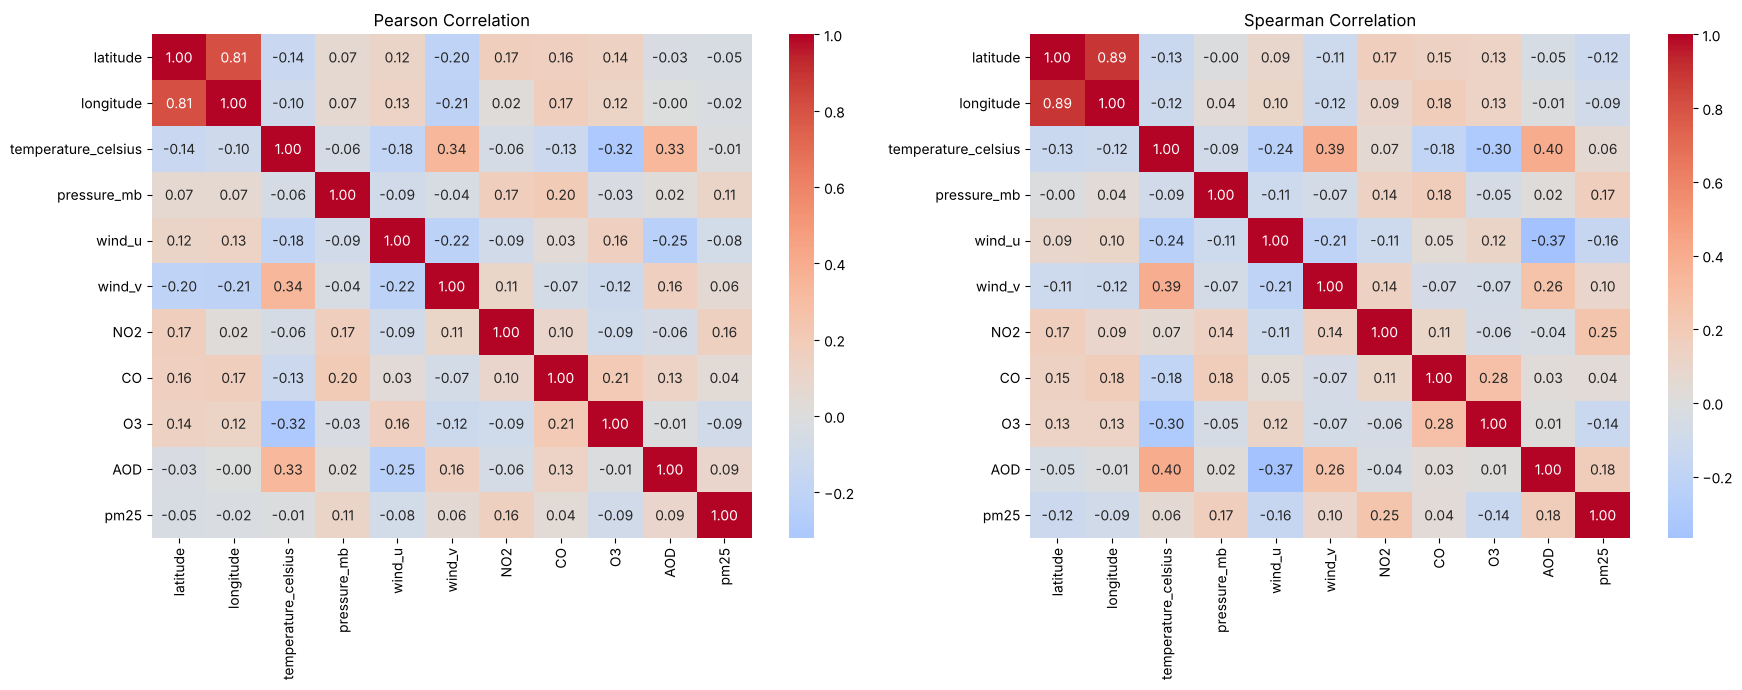

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(pearson_corr, annot=True, cmap="coolwarm",
            center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Pearson Correlation")

sns.heatmap(spearman_corr, annot=True, cmap="coolwarm",
            center=0, fmt=".2f", ax=axes[1])
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

In [ ]:
# Find the strongest correlation for each variable
corr_results = []

for col in pearson_corr.columns:
    correlations = pearson_corr[col].drop(col)
    partner = correlations.abs().idxmax()

    corr_results.append({
        "variable": col,
        "corr_partner": partner,
        "max_abs_corr": abs(correlations[partner])
    })

corr_results = pd.DataFrame(corr_results)

print(corr_results.round(3).to_string(index=False))

print("\nHighly correlated pairs (|r| > 0.9):")
for i in range(len(pearson_corr.columns)):
    for j in range(i + 1, len(pearson_corr.columns)):
        r = pearson_corr.iloc[i, j]
        if abs(r) > 0.9:
            print(pearson_corr.columns[i], "-", pearson_corr.columns[j], ":", round(r, 3))

           variable        corr_partner  max_abs_corr
           latitude           longitude         0.806
          longitude            latitude         0.806
temperature_celsius              wind_v         0.338
        pressure_mb                  CO         0.198
             wind_u                 AOD         0.247
             wind_v temperature_celsius         0.338
                NO2            latitude         0.170
                 CO                  O3         0.210
                 O3 temperature_celsius         0.320
                AOD temperature_celsius         0.332
               pm25                 NO2         0.159

Highly correlated pairs (|r| > 0.9):


In [ ]:
spearman_results = []

for col in spearman_corr.columns:
    correlations = spearman_corr[col].drop(col)
    partner = correlations.abs().idxmax()

    spearman_results.append({
        "variable": col,
        "corr_partner": partner,
        "max_abs_corr": abs(correlations[partner])
    })

print(pd.DataFrame(spearman_results).round(3).to_string(index=False))

           variable        corr_partner  max_abs_corr
           latitude           longitude         0.893
          longitude            latitude         0.893
temperature_celsius                 AOD         0.403
        pressure_mb                  CO         0.182
             wind_u                 AOD         0.367
             wind_v temperature_celsius         0.392
                NO2                pm25         0.247
                 CO                  O3         0.278
                 O3 temperature_celsius         0.299
                AOD temperature_celsius         0.403
               pm25                 NO2         0.247


### 2.4 PM2.5 by station

In [ ]:
station_pm25 = df.groupby("sensor_name")["pm25"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

print(station_pm25.to_string())

                                      count   mean  median   min     max    std
sensor_name                                                                    
AIX CENTRE ECOLE ART                    458   7.14    5.76  0.90   33.60   4.82
AIX ROY RENE                            198  10.01    9.12  2.70   30.66   5.01
ALBALAT DELS TARONGERS                  798   3.74    2.50  0.04   32.62   4.01
ALCANTARILLA                            268  11.11    9.44  1.92   47.41   7.07
ALCORA                                  761   7.28    5.53  0.12  303.50  12.15
ALGAR DE PALÀNCIA                       771   4.65    3.76  0.04   31.35   3.98
ALMASSORA-C. P. OCHANDO                 739   7.28    4.92  0.12  125.25   8.74
ALUMBRES                                197   9.34    7.64  2.01   62.76   6.25
Albors - Valencia                        57  14.27    7.35  0.30   54.05  14.32
Armilla Center                          184   8.84    4.75  0.06   46.31  10.03
Avinguda Meridiana, Sagerra             

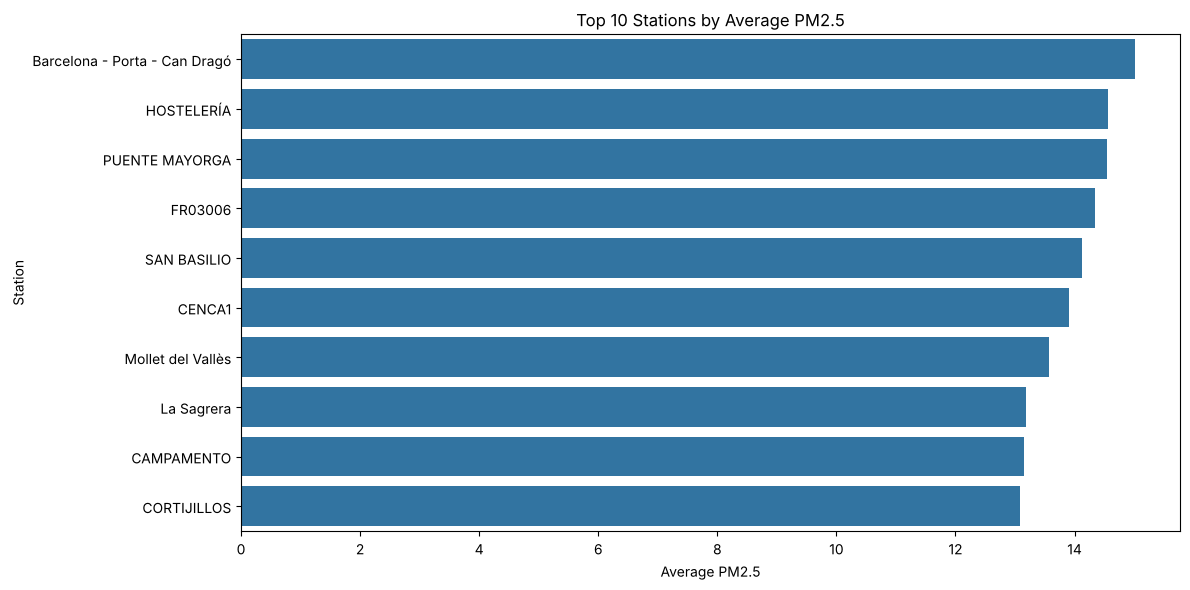

In [ ]:
reliable_stations = station_pm25[station_pm25["count"] >= 100]

top10 = reliable_stations.sort_values(
    by="mean", ascending=False
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top10["mean"], y=top10.index)

plt.title("Top 10 Stations by Average PM2.5")
plt.xlabel("Average PM2.5")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

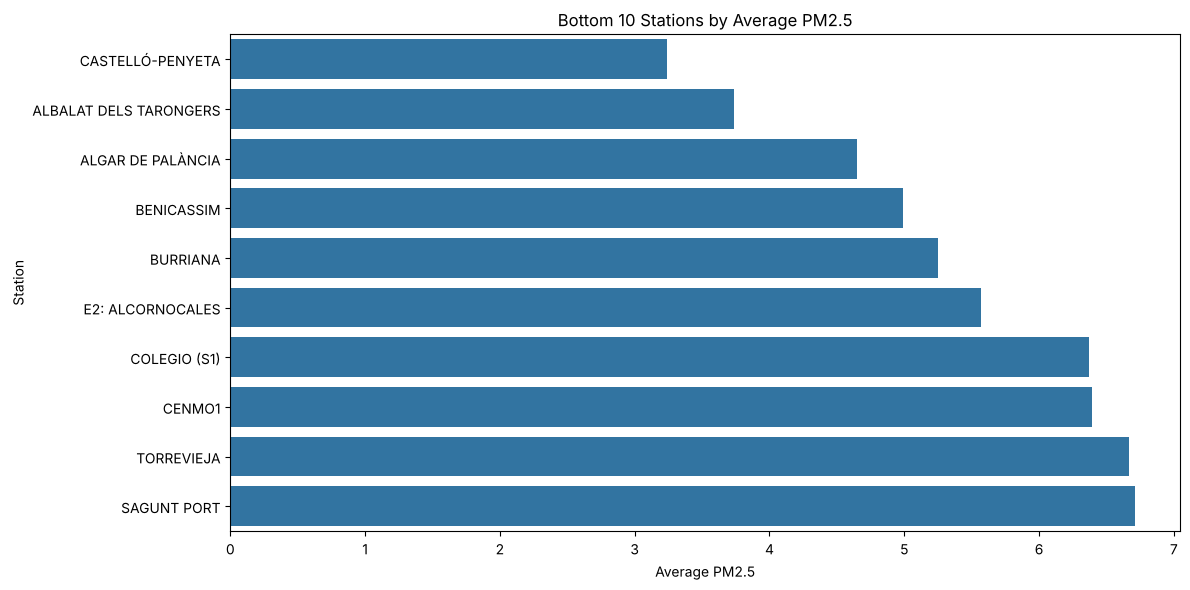

In [ ]:
bottom10 = reliable_stations.sort_values(
    by="mean", ascending=True
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=bottom10["mean"], y=bottom10.index)

plt.title("Bottom 10 Stations by Average PM2.5")
plt.xlabel("Average PM2.5")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

### 2.5 PM2.5 by season

In [ ]:
dates = pd.to_datetime(df["date"])

df["season"] = dates.dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

season_pm25 = df.groupby("season")["pm25"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

print(season_pm25.to_string())

        count   mean  median   min     max    std
season                                           
Autumn  10003   9.08    7.47  0.01  484.98  12.02
Spring   9276   8.25    6.83  0.01  303.50   7.40
Summer  12766   9.59    8.50  0.02  234.88   7.21
Winter   8938  10.94    8.77  0.03  399.40  11.72


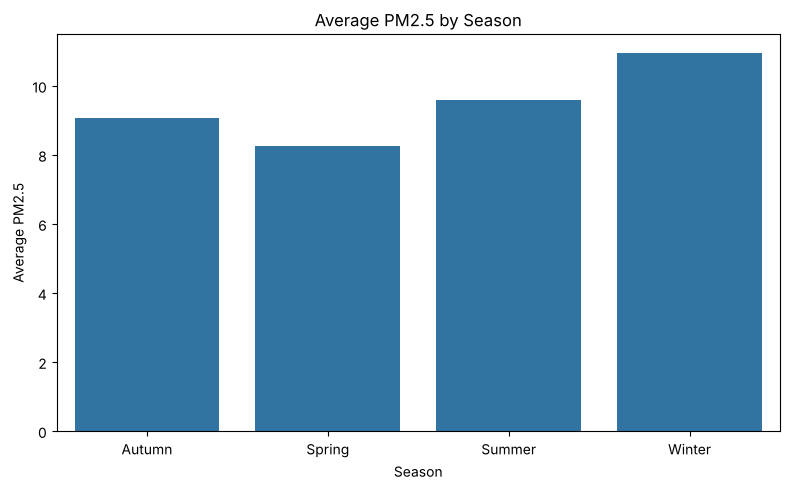

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=season_pm25.reset_index(),
    x="season",
    y="mean"
)

plt.title("Average PM2.5 by Season")
plt.xlabel("Season")
plt.ylabel("Average PM2.5")
plt.tight_layout()
plt.show()

### 2.6 Days above the PM2.5 thresholds (25 and 50 ug/m3)

In [ ]:
total = df["pm25"].count()

above_25 = (df["pm25"] > 25).sum()
above_50 = (df["pm25"] > 50).sum()

print("Total observations:", total)

print("PM2.5 > 25:")
print("Count:", above_25)
print("Percentage:", round(above_25 / total * 100, 2), "%")

print("\nPM2.5 > 50:")
print("Count:", above_50)
print("Percentage:", round(above_50 / total * 100, 2), "%")

Total observations: 40983
PM2.5 > 25:
Count: 1223
Percentage: 2.98 %

PM2.5 > 50:
Count: 117
Percentage: 0.29 %


### 2.7 Skewness, kurtosis and IQR outliers of all numeric variables

In [ ]:
shape_stats = df.select_dtypes(include="number").drop(columns=["id"]).agg(
    ["skew", "kurt"]
).T

shape_stats.columns = ["skewness", "kurtosis"]

print(shape_stats.round(4).to_string())

                     skewness  kurtosis
latitude               0.3970   -0.6863
longitude              0.6438    0.1583
temperature_celsius   -0.1023   -0.9712
pressure_mb           -1.0869    0.7143
wind_u                -0.1778    1.0342
wind_v                -1.2766    4.3890
NO2                    2.1227    9.1775
CO                     1.3982   13.7684
O3                     1.1505    2.2781
AOD                    7.6114  246.8519
pm25                  17.8291  651.6721


In [ ]:
numeric_df = df.select_dtypes(include="number").drop(columns=["id"])

iqr_results = []

for col in numeric_df.columns:
    q1 = numeric_df[col].quantile(0.25)
    q3 = numeric_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_out = ((numeric_df[col] < lower) | (numeric_df[col] > upper)).sum()

    iqr_results.append({
        "variable": col,
        "iqr": iqr,
        "n_out_iqr": n_out,
        "pct_out_iqr": n_out / numeric_df[col].count() * 100
    })

print(pd.DataFrame(iqr_results).round(4).to_string(index=False))

           variable     iqr  n_out_iqr  pct_out_iqr
           latitude  3.2106          0       0.0000
          longitude  4.7623       2079       5.0728
temperature_celsius 10.8221          0       0.0000
        pressure_mb 17.3805       3179       7.7569
             wind_u  2.6691       2133       5.2046
             wind_v  1.3924       2234       5.4510
                NO2  0.0000       2061       5.3427
                 CO  0.0048        572       1.4828
                 O3  0.0170       1219       3.1634
                AOD  0.1140       1114       2.7182
               pm25  7.4128       1613       3.9358


### 2.8 Summary table of the EDA (`Exploratory_Data.csv`)

In [ ]:
model_id = "gru_pm25"
model_group = "G12"

print("Model ID:", model_id)
print("Model Group:", model_group)
print("Variables:", list(numeric_df.columns))

Model ID: gru_pm25
Model Group: G12
Variables: ['latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25']


In [ ]:
summary = pd.DataFrame(index=numeric_df.columns)

summary["n_total"] = len(df)
summary["n_missing"] = df[numeric_df.columns].isnull().sum()
summary["pct_missing"] = df[numeric_df.columns].isnull().mean() * 100
summary["n_unique"] = df[numeric_df.columns].nunique()

summary["min"] = numeric_df.min()
summary["q1"] = numeric_df.quantile(0.25)
summary["median"] = numeric_df.median()
summary["q3"] = numeric_df.quantile(0.75)
summary["max"] = numeric_df.max()
summary["mean"] = numeric_df.mean()
summary["std"] = numeric_df.std()

print(summary.round(6).to_string())

                     n_total  n_missing  pct_missing  n_unique         min          q1      median           q3          max        mean        std
latitude               40983          0     0.000000        95   36.133317   36.841330   39.448330    40.051944    43.530297   39.030362   2.231117
longitude              40983          0     0.000000        95   -5.663500   -3.612660   -0.406050     1.149600     9.136389   -0.466409   3.829059
temperature_celsius    40983          0     0.000000     29394   -1.279053   12.965739   18.494734    23.787869    34.865831   18.271961   6.386195
pressure_mb            40983          0     0.000000     29394  930.317065  987.986366  997.728716  1005.366821  1033.662176  993.817385  17.180014
wind_u                 40983          0     0.000000     29383  -11.098723   -0.984837    0.205846     1.684241     9.661651    0.343444   2.527802
wind_v                 40983          0     0.000000     29399  -10.860048   -0.730883    0.042730     0.661478 

In [ ]:
variable_info = {
    "latitude": ("Spatial", "numeric", "degree"),
    "longitude": ("Spatial", "numeric", "degree"),
    "temperature_celsius": ("Meteorological", "numeric", "°C"),
    "pressure_mb": ("Meteorological", "numeric", "mb"),
    "wind_u": ("Meteorological", "numeric", "m/s"),
    "wind_v": ("Meteorological", "numeric", "m/s"),
    "NO2": ("NO2", "numeric", "dimensionless"),
    "CO": ("CO", "numeric", "dimensionless"),
    "O3": ("O3", "numeric", "dimensionless"),
    "AOD": ("AOD", "numeric", "dimensionless"),
    "pm25": ("Target", "numeric", "μg/m3")
}

info_df = pd.DataFrame.from_dict(
    variable_info,
    orient="index",
    columns=["family", "type", "unit"]
)

print(info_df.to_string())

                             family     type           unit
latitude                    Spatial  numeric         degree
longitude                   Spatial  numeric         degree
temperature_celsius  Meteorological  numeric             °C
pressure_mb          Meteorological  numeric             mb
wind_u               Meteorological  numeric            m/s
wind_v               Meteorological  numeric            m/s
NO2                             NO2  numeric  dimensionless
CO                               CO  numeric  dimensionless
O3                               O3  numeric  dimensionless
AOD                             AOD  numeric  dimensionless
pm25                         Target  numeric          μg/m3


In [ ]:
final_eda = summary.join(info_df)

final_eda.index.name = "variable"

print(final_eda.head().to_string())
print("\nShape:", final_eda.shape)

                     n_total  n_missing  pct_missing  n_unique         min          q1      median           q3          max        mean        std          family     type    unit
variable                                                                                                                                                                            
latitude               40983          0          0.0        95   36.133317   36.841330   39.448330    40.051944    43.530297   39.030362   2.231117         Spatial  numeric  degree
longitude              40983          0          0.0        95   -5.663500   -3.612660   -0.406050     1.149600     9.136389   -0.466409   3.829059         Spatial  numeric  degree
temperature_celsius    40983          0          0.0     29394   -1.279053   12.965739   18.494734    23.787869    34.865831   18.271961   6.386195  Meteorological  numeric      °C
pressure_mb            40983          0          0.0     29394  930.317065  987.986366  997.728

In [ ]:
iqr_df = pd.DataFrame(iqr_results).set_index("variable")
corr_df = pd.DataFrame(corr_results).set_index("variable")

final_eda = final_eda.join(shape_stats)
final_eda = final_eda.join(iqr_df)
final_eda = final_eda.join(corr_df)

final_eda["model_id"] = "gru_pm25"
final_eda["model_group"] = "G12"

final_eda.index.name = "variable"

print("Shape:", final_eda.shape)
print(final_eda.head().to_string())

Shape: (11, 23)
                     n_total  n_missing  pct_missing  n_unique         min          q1      median           q3          max        mean        std          family     type    unit  skewness  kurtosis        iqr  n_out_iqr  pct_out_iqr corr_partner  max_abs_corr  model_id model_group
variable                                                                                                                                                                                                                                                                                    
latitude               40983          0          0.0        95   36.133317   36.841330   39.448330    40.051944    43.530297   39.030362   2.231117         Spatial  numeric  degree  0.396995 -0.686293   3.210614          0     0.000000    longitude      0.806485  gru_pm25         G12
longitude              40983          0          0.0        95   -5.663500   -3.612660   -0.406050     1.149600     9.136389   -0

In [ ]:
target_assoc = {}

for col in pearson_corr.columns:
    if col == "pm25":
        target_assoc[col] = "target_variable"
    else:
        p = pearson_corr.loc[col, "pm25"]
        s = spearman_corr.loc[col, "pm25"]

        target_assoc[col] = (
            f"pearson_r={p:.4f}; spearman_r={s:.4f}"
        )

final_eda["target_assoc"] = pd.Series(target_assoc)

print(final_eda[["target_assoc"]].to_string())

                                              target_assoc
variable                                                  
latitude             pearson_r=-0.0460; spearman_r=-0.1218
longitude            pearson_r=-0.0228; spearman_r=-0.0888
temperature_celsius   pearson_r=-0.0060; spearman_r=0.0642
pressure_mb            pearson_r=0.1133; spearman_r=0.1671
wind_u               pearson_r=-0.0786; spearman_r=-0.1635
wind_v                 pearson_r=0.0595; spearman_r=0.0972
NO2                    pearson_r=0.1593; spearman_r=0.2468
CO                     pearson_r=0.0415; spearman_r=0.0363
O3                   pearson_r=-0.0872; spearman_r=-0.1351
AOD                    pearson_r=0.0942; spearman_r=0.1801
pm25                                       target_variable


Checks coming from Part 1 (the cleaning must leave no invalid PM2.5 and no duplicate key):

In [ ]:
print("PM2.5 <= 0:", (df["pm25"] <= 0).sum())
print("PM2.5 >= 500:", (df["pm25"] >= 500).sum())

duplicates = df.duplicated(subset=["date", "latitude", "longitude", "sensor_name"]).sum()
print("Duplicate keys:", duplicates)

PM2.5 <= 0: 0
PM2.5 >= 500: 0
Duplicate keys: 0


In [ ]:
cleaning_log = pd.read_csv("cleaning_log.csv")
print(cleaning_log.to_string())

# rows removed in Part 1 for the file used here (combined_gee_pm25.csv)
n_removed = int(cleaning_log.loc[cleaning_log["file"] == "combined_gee_pm25.csv", "removed_total"].iloc[0])
print("\nRows removed from combined_gee_pm25.csv:", n_removed)

                    file  rows_before  removed_missing_pm25  removed_pm25_le_0  removed_pm25_ge_500  removed_total  rows_after  pct_removed
0               pm25.csv        88041                     0               2093                   19           2112       85929         2.40
1  combined_gee_pm25.csv        41718                     0                727                    8            735       40983         1.76

Rows removed from combined_gee_pm25.csv: 735


In [ ]:
# sentinel / duplicate / cleaning information (only meaningful for the target)
final_eda["n_sentinel_low"] = np.nan
final_eda["n_sentinel_high"] = np.nan
final_eda.loc["pm25", "n_sentinel_low"] = (df["pm25"] <= 0).sum()
final_eda.loc["pm25", "n_sentinel_high"] = (df["pm25"] >= 500).sum()
final_eda["n_duplicates_key"] = duplicates
final_eda["n_removed_total"] = n_removed

# units of the Sentinel-5P / AOD variables are not written in the files
final_eda.loc[["NO2", "CO", "O3", "AOD"], "unit"] = "unknown"

print("Shape:", final_eda.shape)
print("\nColumns:")
print(final_eda.columns.tolist())
print("\nMissing cells per column of the summary table (NaN is expected for n_sentinel_* on non-target rows):")
print(final_eda.isnull().sum()[lambda s: s > 0].to_string())
print()
print(final_eda[["family", "type", "unit", "n_sentinel_low", "n_sentinel_high", "n_duplicates_key", "n_removed_total"]].to_string())

Shape: (11, 28)

Columns:
['n_total', 'n_missing', 'pct_missing', 'n_unique', 'min', 'q1', 'median', 'q3', 'max', 'mean', 'std', 'family', 'type', 'unit', 'skewness', 'kurtosis', 'iqr', 'n_out_iqr', 'pct_out_iqr', 'corr_partner', 'max_abs_corr', 'model_id', 'model_group', 'target_assoc', 'n_sentinel_low', 'n_sentinel_high', 'n_duplicates_key', 'n_removed_total']

Missing cells per column of the summary table (NaN is expected for n_sentinel_* on non-target rows):
n_sentinel_low     10
n_sentinel_high    10

                             family     type     unit  n_sentinel_low  n_sentinel_high  n_duplicates_key  n_removed_total
variable                                                                                                                 
latitude                    Spatial  numeric   degree             NaN              NaN                 0              735
longitude                   Spatial  numeric   degree             NaN              NaN                 0              735


In [ ]:
final_eda.to_csv("Exploratory_Data.csv", index=True)
print("File saved successfully!")

File saved successfully!


In [ ]:
# download the table (works only in Google Colab)
try:
    from google.colab import files
    files.download("Exploratory_Data.csv")
except ImportError:
    print("Not in Colab: the file stays in the working folder.")